# <font face = 'Impact' color = '#E7625F' > Sample Demonstration on Machine Learning for Regression: Health Care Cost Estimates<font/>
#### <font face = 'Times New Roman' color = '#1F6CB0'> License: GPL v3.0<font/>
#### <font face = 'Times New Roman' color = '#1F6CB0'> Author and Trainer: Paolo Hilado MSc. (Data Science)<font/>
This notebook provides a backgrounder in doing Machine Learning in Python employing models such as Ridge Regression, LASSO Regression, Elastic Net, Regression Tree, and Random Forest.

# Business Understanding

## 1.1 Business Context
A hypothetical health company, Health Care Analytics, wants to improve the way it estimates health care costs and relevant features

The company wants to use machine learning to develop a data-driven system that can estimate the said response variable 

The proposed machine-learning solution will use historical property information such as:  

- patient_id
- age
- gender
- bmi
- chronic_conditions
- smoking_status
- physical_activity_level
- hospital_visits
- doctor_visits
- medications_count
- previous_hospitalization
- health_risk_score
- insurance_type
- preventive_care_visits
- annual_healthcare_cost	Float

The target variable will be the health care cost, making this a supervised regression problem.

## 1.2 Business Problem  
HealthCare Analytics currently relies on basic calculations and general historical cost estimates to understand potential healthcare expenses. This can lead to inconsistent cost estimates, particularly for patients with different medical conditions, lifestyle factors, and healthcare utilization patterns.

An inaccurate healthcare cost estimate can result in:

Patients having difficulty planning and budgeting for medical expenses.

Healthcare providers facing challenges in estimating potential treatment costs.

Insurance providers having difficulty analyzing expected healthcare expenditures.

Healthcare administrators struggling to allocate budgets and resources effectively.

Increased time required to assess and compare estimated healthcare expenses.

The business therefore needs a systematic, data-driven method for estimating annual healthcare costs based on relevant patient and healthcare-related factors.

## 1.3 Business Objective  
The main objectives of this project are to:

Develop a machine-learning model that estimates annual healthcare costs.

Compare regression algorithms to determine which provides the most accurate predictions.

Evaluate model performance using metrics such as  Root Mean Squared Error (RMSE) and R-squared

Support healthcare budgeting, financial planning, and cost analysis through data-driven estimates.

## 1.4 Data Mining Objective
The data-mining objective is to develop a regression model that predicts the continuous variable:  

### annual_healthcare_cost

using health related variables.  

The analysis will involve:  

- Loading and exploring the dataset.
- Performing Exploratory Data Analysis
- Data Partitioning
- Data Preprocessing (Feature Scaling and One-hot Coding) and Data Cleaning (when needed)
- Machine Learning Development and Performance Evaluation using RMSE and R-squared


## 1.5 Business Assumptions  
The hypothetical project makes the following assumptions:  

- Availability of patient demographic and healthcare-related data.
- Patients with chronic conditions are assumed to have higher healthcare costs.
- Older patients are assumed to have higher healthcare expenses on average.
- Higher healthcare utilization is assumed to be associated with increased annual costs.
- A greater number of medications is assumed to increase healthcare expenses.
- Lifestyle factors may influence healthcare costs.
- Preventive care visits may affect future healthcare expenses.
- Insurance type may influence healthcare access and out-of-pocket expenses.
- Annual healthcare costs are measured in Philippine pesos (PHP)

## 1.6 Success Criteria
Business Success Criteria  
The project will be considered successful if the resulting model:  

Provides reasonably accurate health care cost estimates.  
Performs better than a simple baseline prediction, such as predicting health care cost.  
Can support health care insurance agents in making consistent estimates of health care cost.  
Produces predictions that are sufficiently reliable for initial health care assessment.  

R² ≥ 0.80 on the test dataset.  
RMSE should be reasonably small relative to the health care cost.  
The model should not exhibit a large difference between training and testing performance, indicating severe overfitting.  
These thresholds are illustrative and would need to be validated with actual health care stakeholders using real health data.  

# 2. Data Understanding

## 2.1 Data Owner
The hypothetical data owner is:  

Healthcare Analytics – Property Valuation Department  

Because this is a hypothetical project, the organization and dataset do not represent an actual company or proprietary database.  

## 2.2 Data Source
The dataset is hypothetical and synthetically generated for educational and demonstration purposes. It is not collected from real patients, hospitals, insurance providers, or healthcare transactions. 

## 2.3 Data Licensing
The dataset is hypothetical and synthetically generated for educational and demonstration purposes.  
License: Creative Commons Attribution 4.0 International (CC BY 4.0), for the purposes of this demonstration.  
No real personal information or health information is included.  
If this project were later converted to use real data, the licensing terms would need to be reviewed before the data could be distributed or used for modeling.  

## 2.4 Data Format
The dataset is in a CSV format.  
The dataset contains both numerical and categorical variables.  

## 2.5 Dataset Dimensions
For this project, we will generate:  

1,000 observations (rows)  
15 columns  

## 2.6 Data Dictionary

| Variable | Data Type | Description | Role |
|---|---|---|---|
| `patient_id` | String | Unique identifier assigned to each patient | Identifier |
| `age` | Integer | Age of the patient in years | Predictor |
| `gender` | Categorical | Gender of the patient | Predictor |
| `bmi` | Float | Body Mass Index of the patient | Predictor |
| `chronic_conditions` | Integer | Number of chronic health conditions diagnosed in the patient | Predictor |
| `smoking_status` | Categorical | Smoking status of the patient | Predictor |
| `physical_activity_level` | Categorical | Level of regular physical activity | Predictor |
| `hospital_visits` | Integer | Number of hospital visits during the year | Predictor |
| `doctor_visits` | Integer | Number of doctor or clinic visits during the year | Predictor |
| `medications_count` | Integer | Number of prescribed medications used by the patient | Predictor |
| `previous_hospitalization` | Integer | Whether the patient had a previous hospitalization (0 = No, 1 = Yes) | Predictor |
| `health_risk_score` | Float | Overall health-risk score assigned to the patient | Predictor |
| `insurance_type` | Categorical | Type of healthcare insurance coverage | Predictor |
| `preventive_care_visits` | Integer | Number of preventive healthcare visits during the year | Predictor |
| `annual_healthcare_cost` | Float | Hypothetical annual healthcare expenditure for the patient | Target |


In [1]:
# Load the data set
import pandas as pd
df = pd.read_csv("healthcare_cost_dataset.csv")
df.head(3)

,patient_id,age,gender,bmi,chronic_conditions,smoking_status,physical_activity_level,hospital_visits,doctor_visits,medications_count,previous_hospitalization,health_risk_score,insurance_type,preventive_care_visits,annual_healthcare_cost
0,P0001,56,Female,29.68,3,Never,High,3,3,5,0,46.56,Standard,0,31587.33
1,P0002,69,Male,30.84,0,Never,High,2,1,3,0,56.38,Basic,1,23368.06
2,P0003,46,Female,30.42,1,Never,Low,3,4,0,0,72.69,Premium,0,28356.67


In [2]:
# Checked the structure of the dataframe
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                1000 non-null   str    
 1   age                       1000 non-null   int64  
 2   gender                    1000 non-null   str    
 3   bmi                       1000 non-null   float64
 4   chronic_conditions        1000 non-null   int64  
 5   smoking_status            1000 non-null   str    
 6   physical_activity_level   1000 non-null   str    
 7   hospital_visits           1000 non-null   int64  
 8   doctor_visits             1000 non-null   int64  
 9   medications_count         1000 non-null   int64  
 10  previous_hospitalization  1000 non-null   int64  
 11  health_risk_score         1000 non-null   float64
 12  insurance_type            1000 non-null   str    
 13  preventive_care_visits    1000 non-null   int64  
 14  annual_healthcare_co


--- Variable: age ---
  Anderson-Darling Statistic : 10.6187
  p-value : 0.0100
  Decision : Reject Null


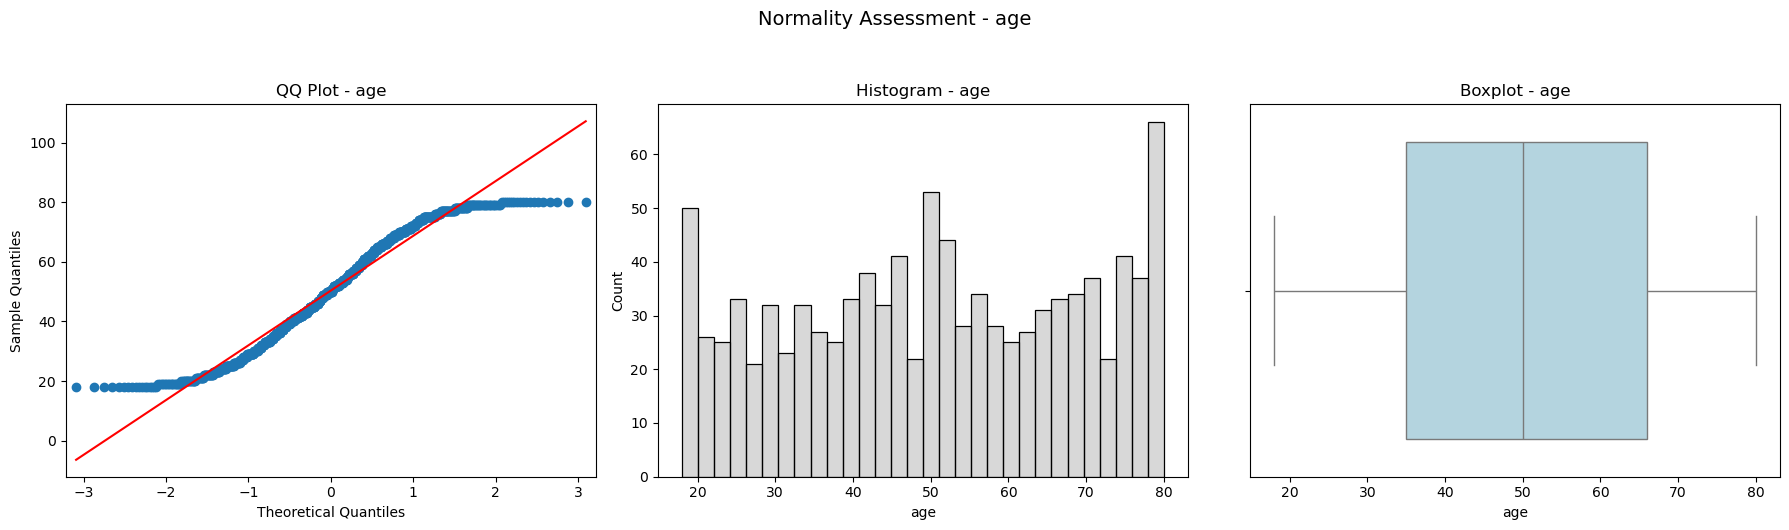


--- Variable: bmi ---
  Anderson-Darling Statistic : 0.1625
  p-value : 0.1500
  Decision : Fail to Reject Null


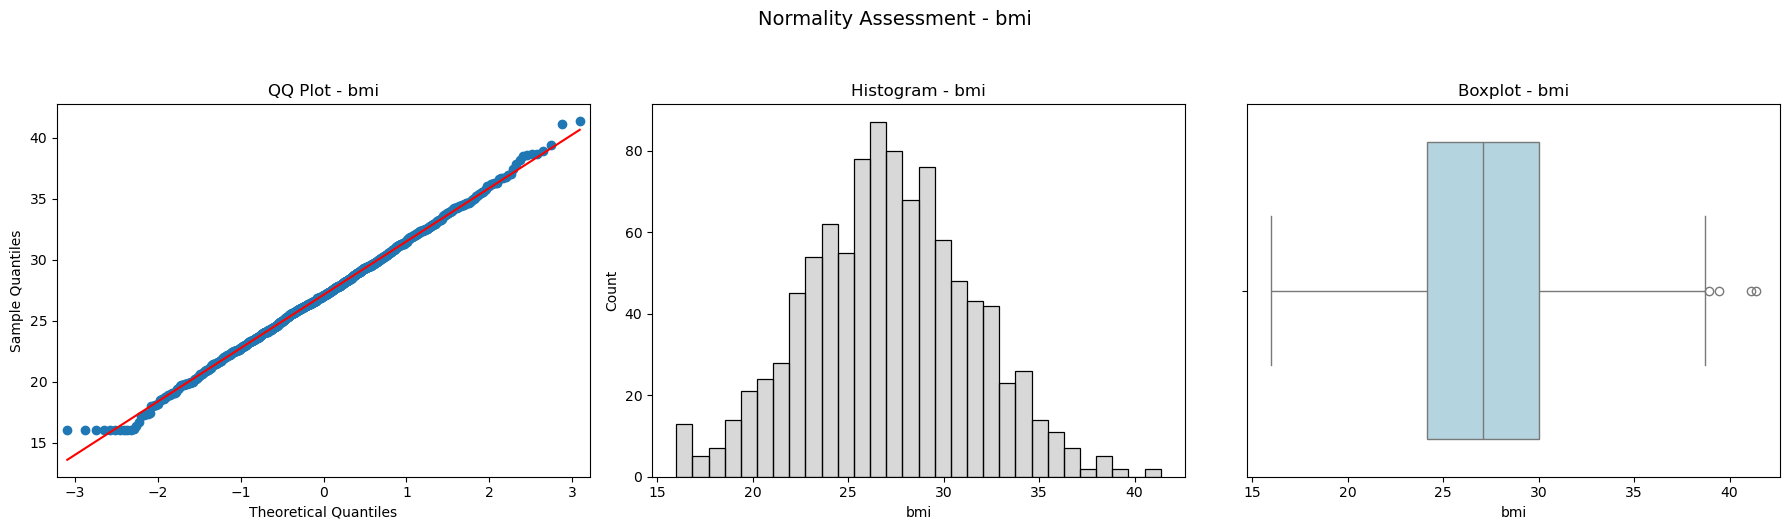


--- Variable: chronic_conditions ---
  Anderson-Darling Statistic : 52.0109
  p-value : 0.0100
  Decision : Reject Null


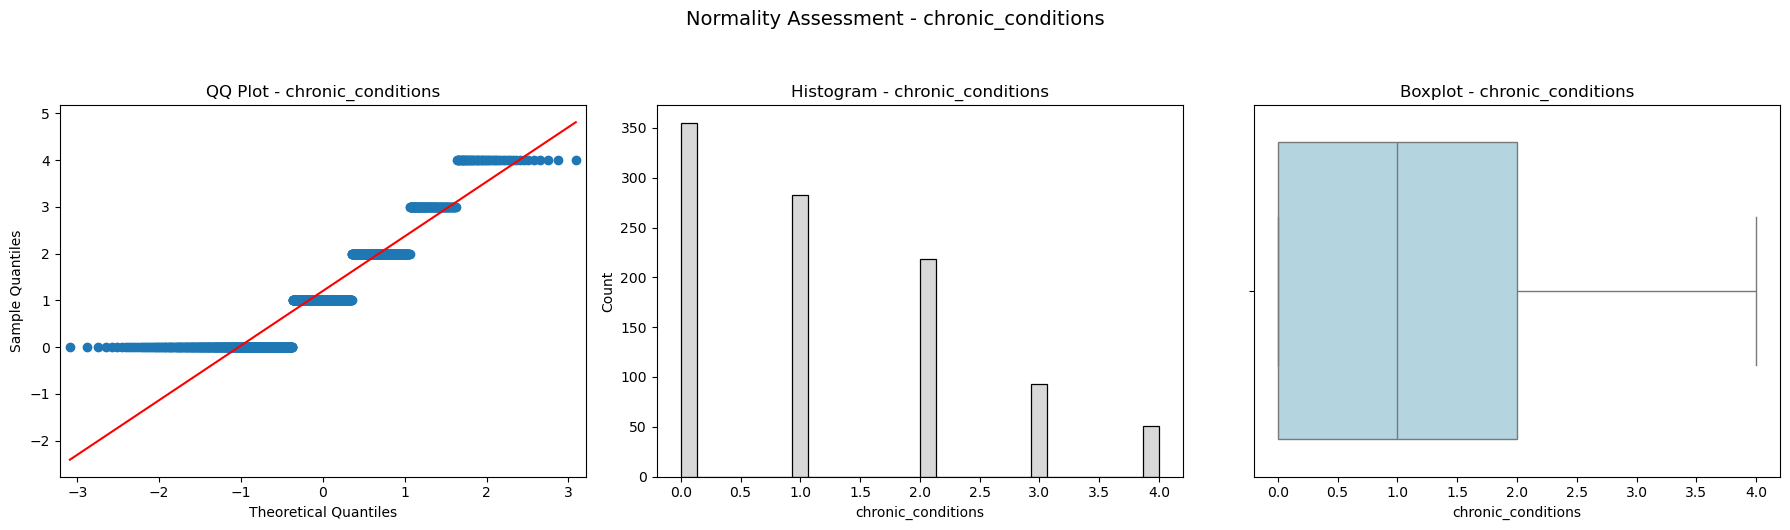


--- Variable: hospital_visits ---
  Anderson-Darling Statistic : 28.2177
  p-value : 0.0100
  Decision : Reject Null


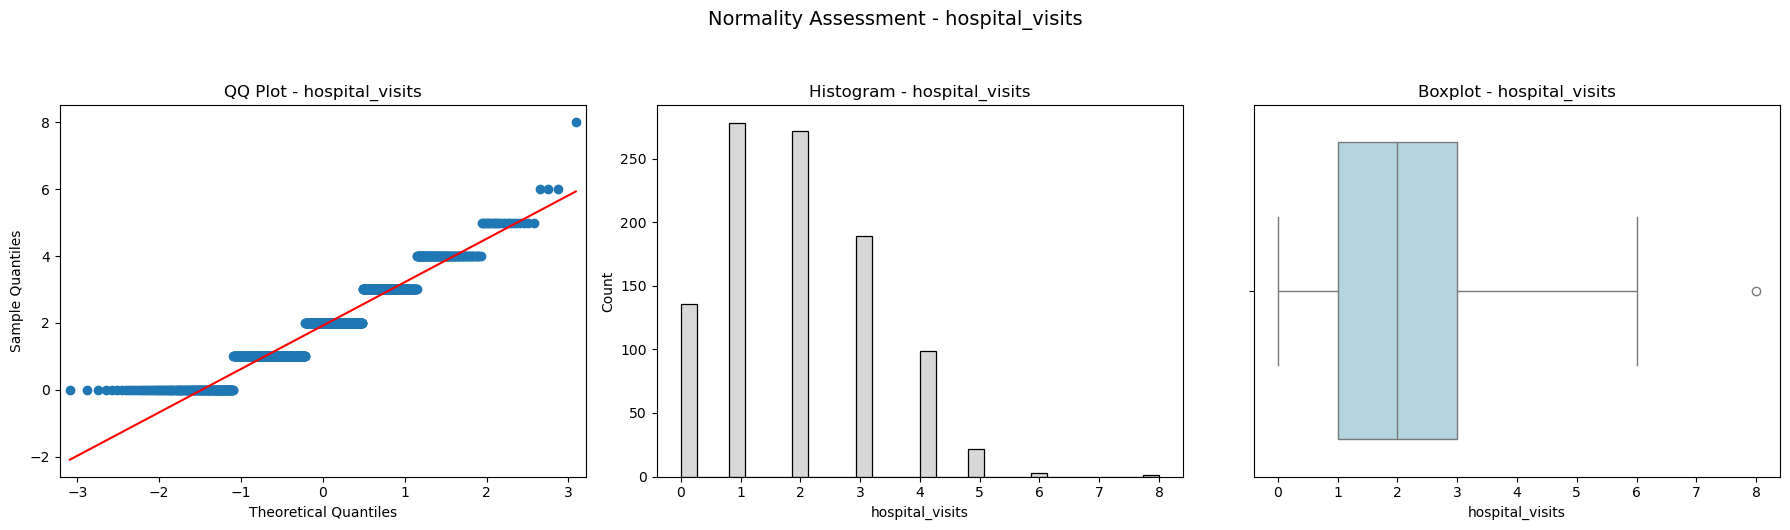


--- Variable: doctor_visits ---
  Anderson-Darling Statistic : 12.1031
  p-value : 0.0100
  Decision : Reject Null


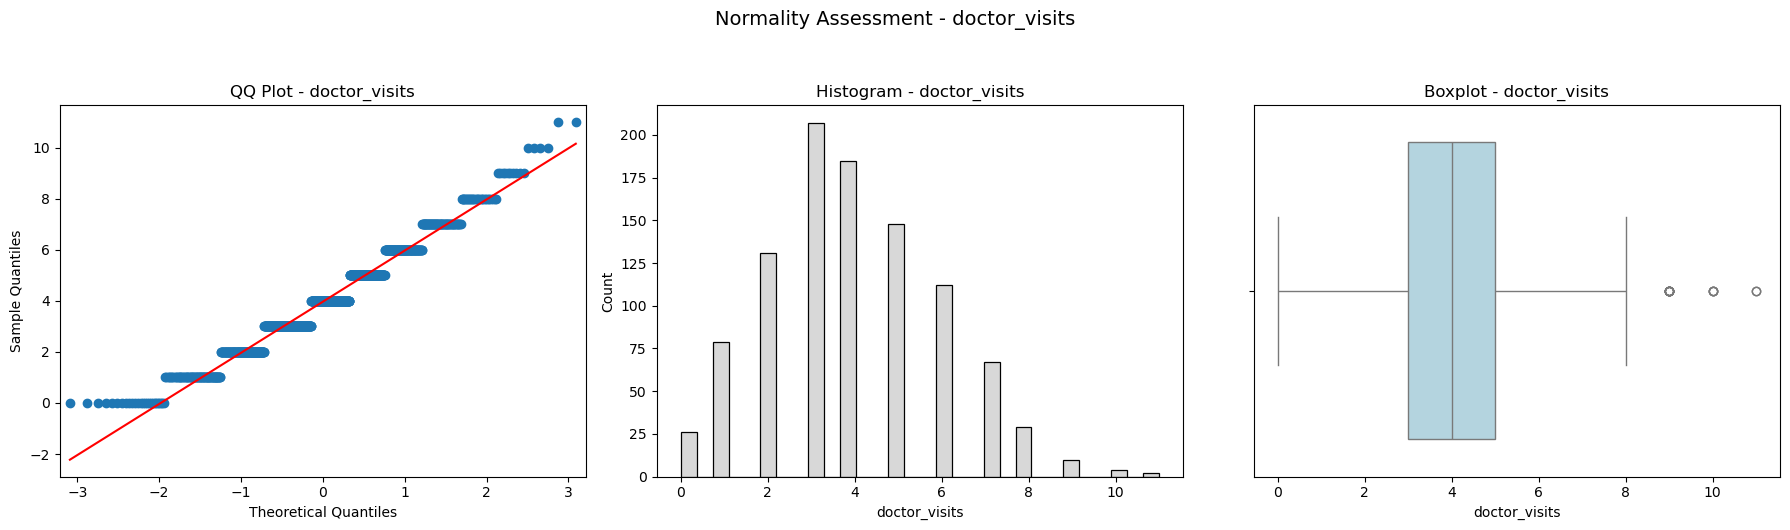


--- Variable: medications_count ---
  Anderson-Darling Statistic : 23.1106
  p-value : 0.0100
  Decision : Reject Null


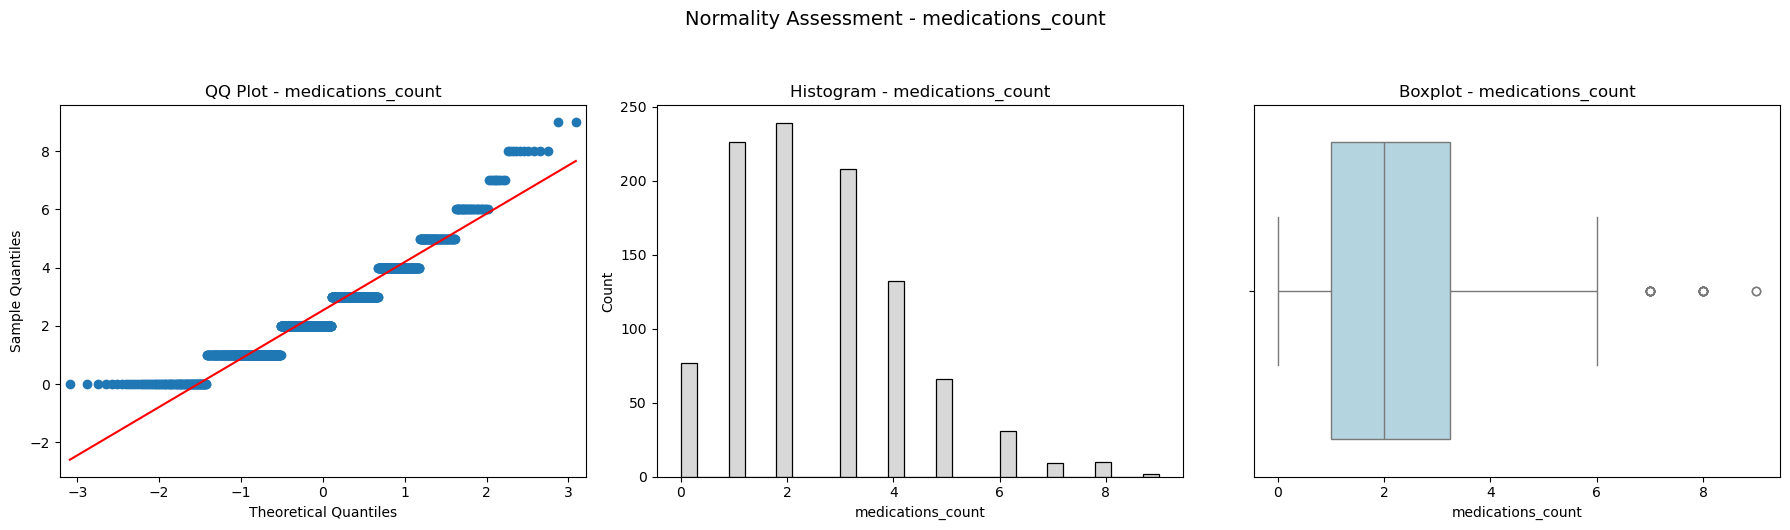


--- Variable: previous_hospitalization ---
  Anderson-Darling Statistic : 242.2956
  p-value : 0.0100
  Decision : Reject Null


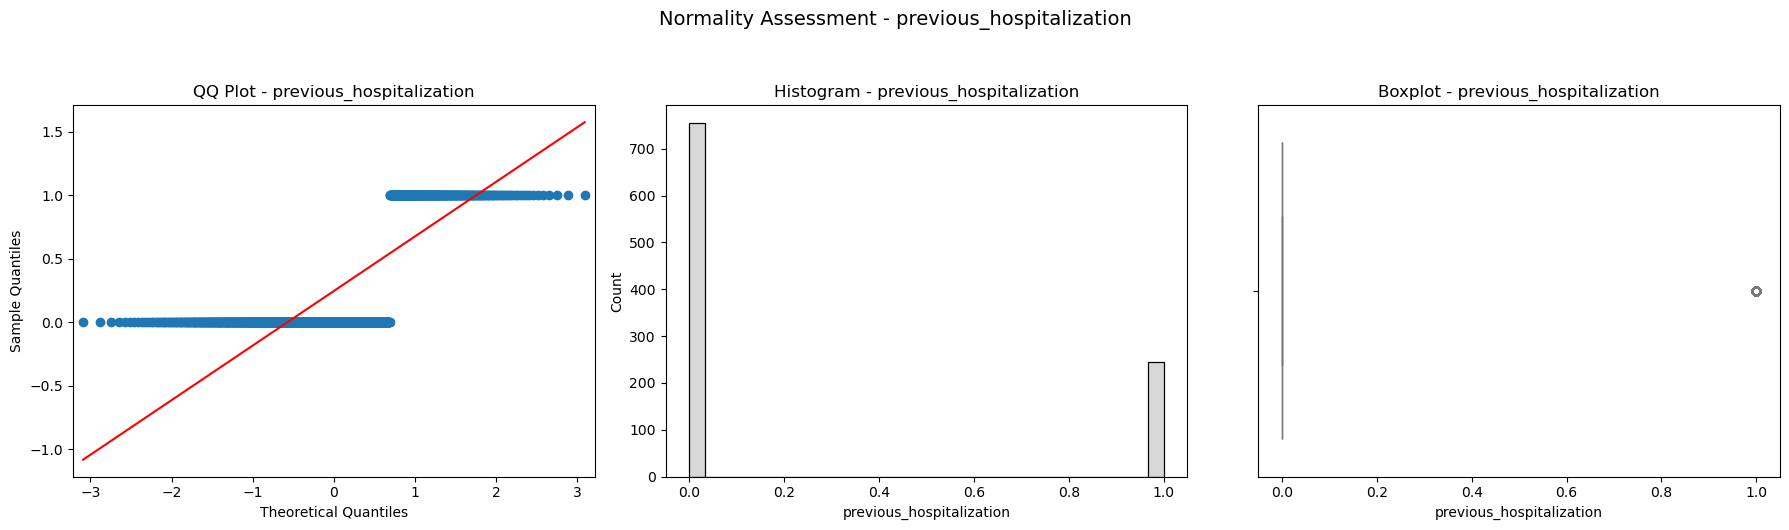


--- Variable: health_risk_score ---
  Anderson-Darling Statistic : 1.0251
  p-value : 0.0108
  Decision : Reject Null


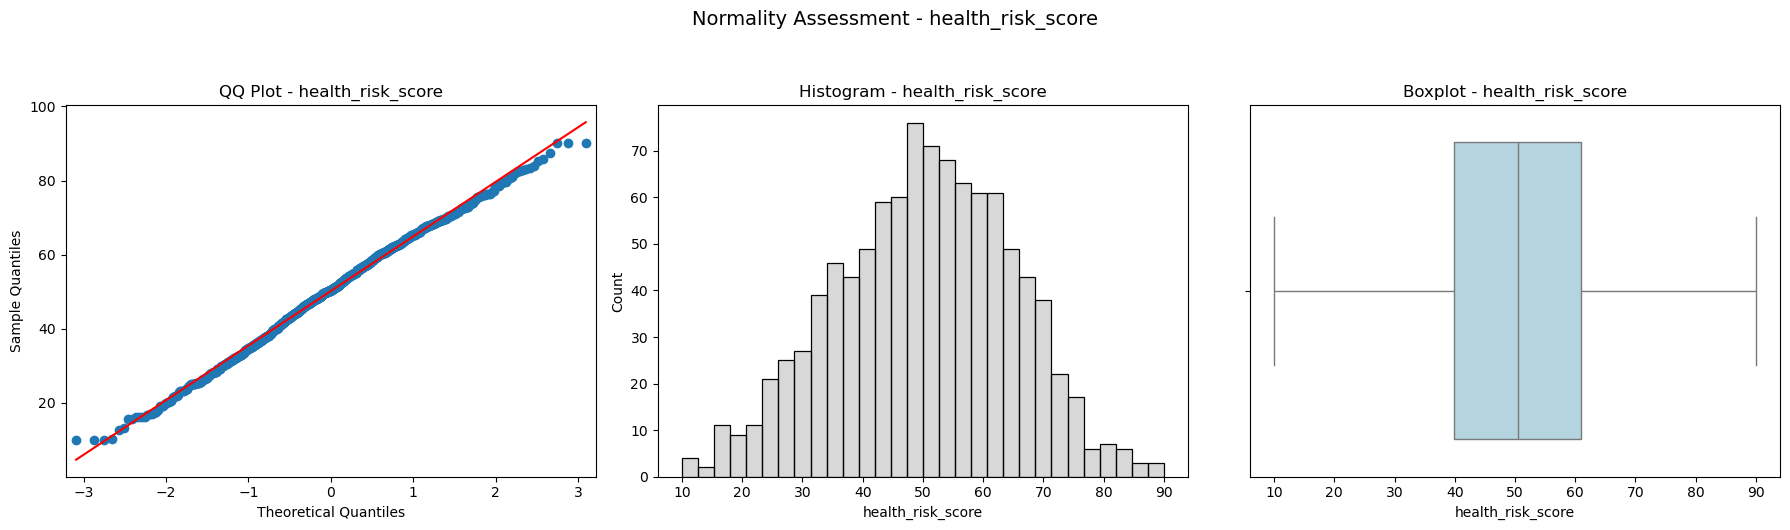


--- Variable: preventive_care_visits ---
  Anderson-Darling Statistic : 37.2403
  p-value : 0.0100
  Decision : Reject Null


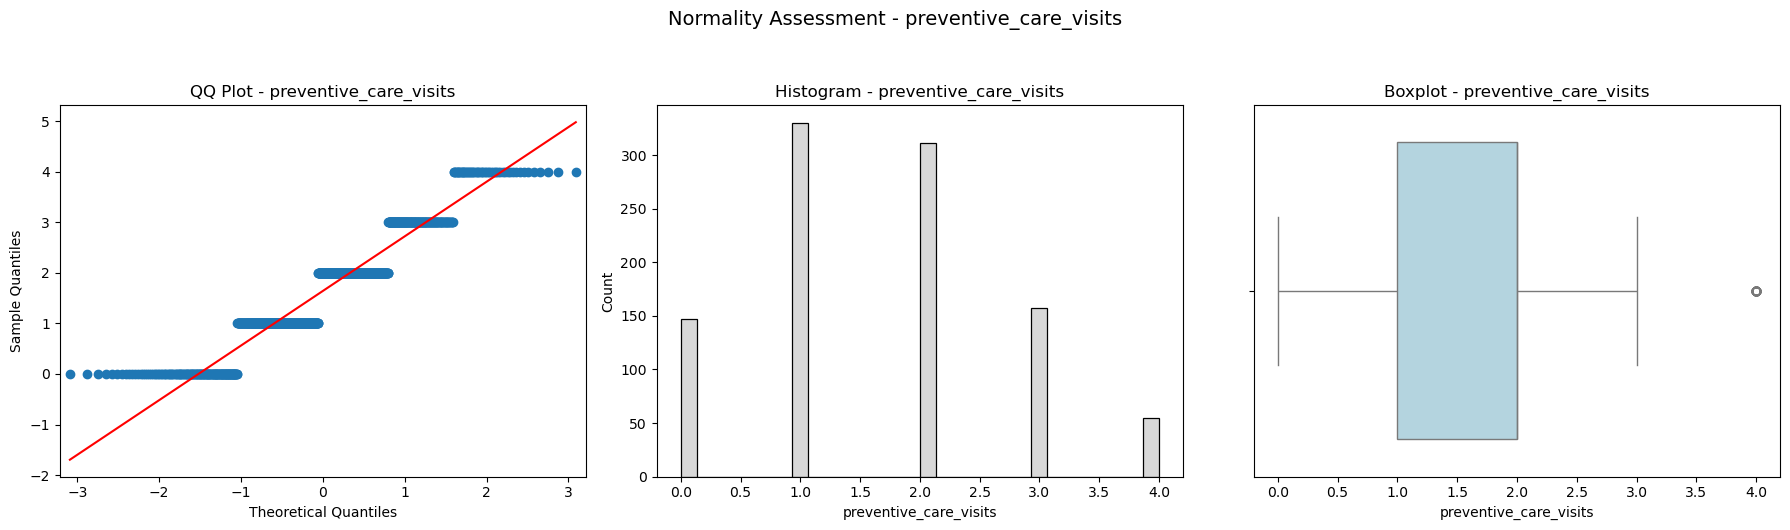


--- Variable: annual_healthcare_cost ---
  Anderson-Darling Statistic : 0.8884
  p-value : 0.0235
  Decision : Reject Null


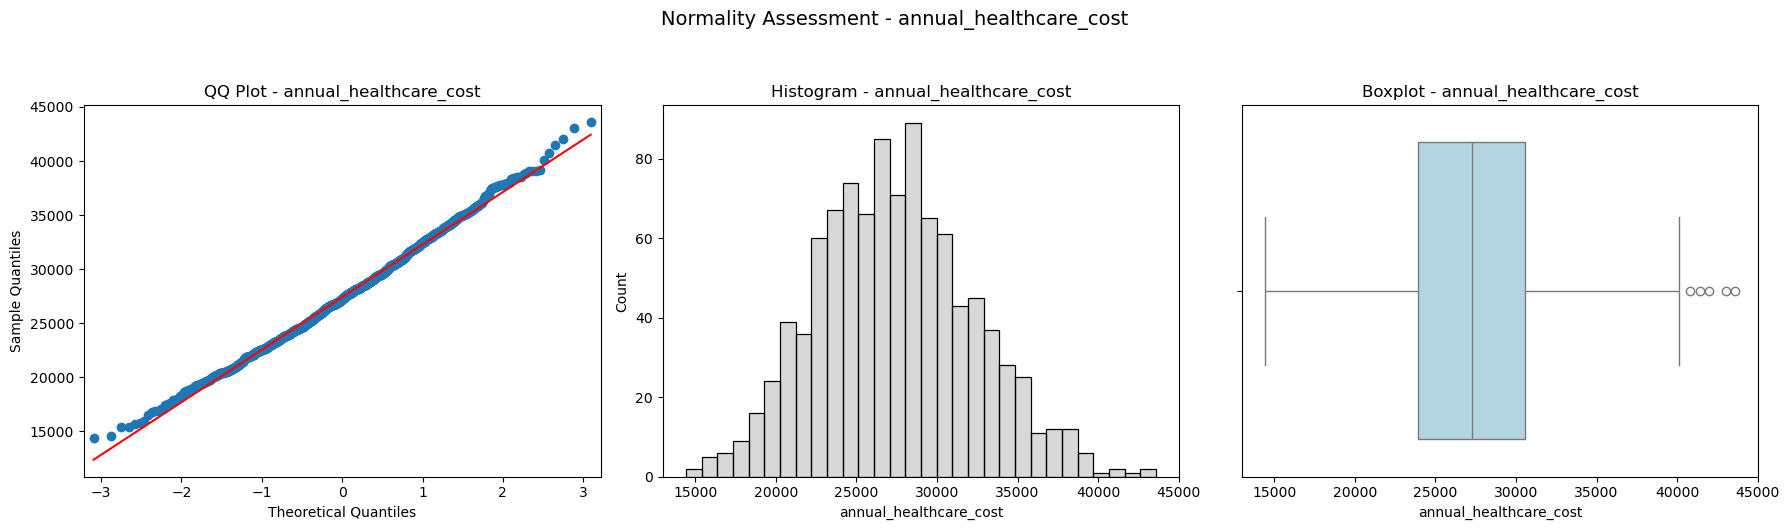

In [3]:
# Initial Exploratory Data Analysis
import qdesc as qd
qd.normcheck_dashboard(df)

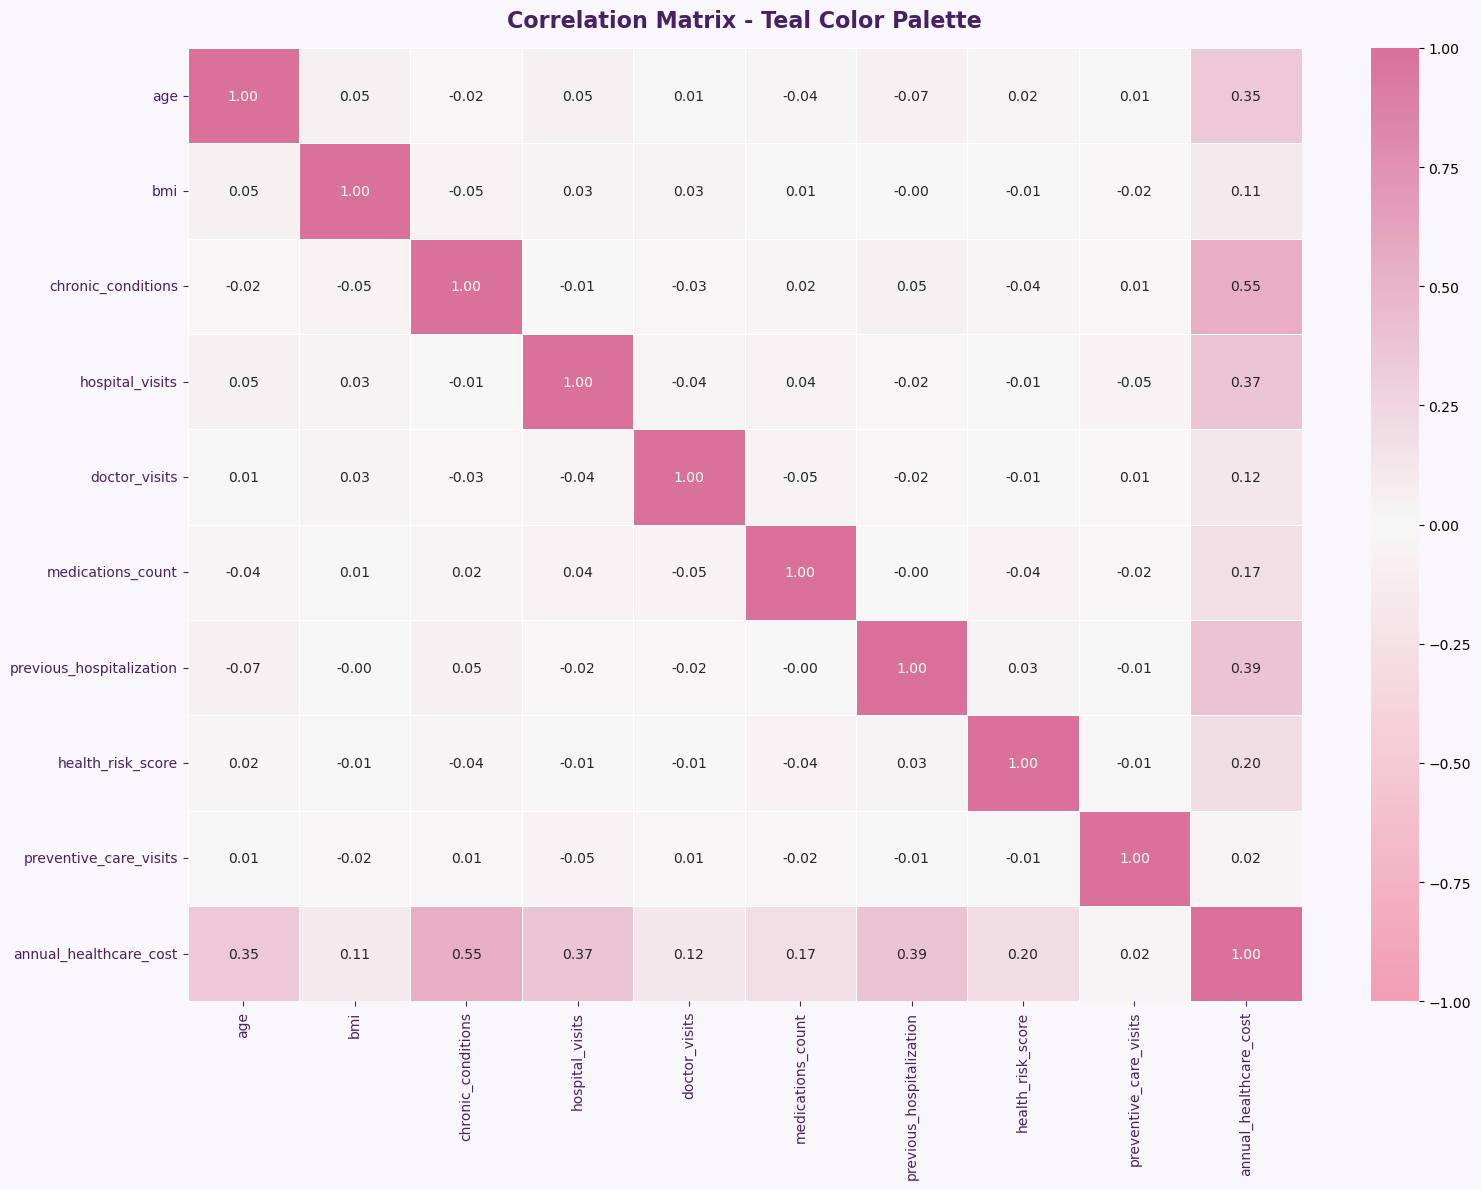

In [4]:
# Check for strong correlations amongst our explanatory variables
qd.corr_heatmap(df, method="spearman", palette="rose", title="Correlation Matrix - Teal Color Palette")

In [5]:
# Compute the Variance Inflation Factor to check for multicollinearity
qd.vif(df, exclude = "annual_healthcare_cost")

,Feature,VIF
0,age,1.013244
1,previous_hospitalization,1.010630
2,medications_count,1.009616
3,hospital_visits,1.008835
4,chronic_conditions,1.008687
5,bmi,1.008192
6,doctor_visits,1.008088
7,health_risk_score,1.004629
8,preventive_care_visits,1.003633


# Preprocessing for Machine Learning

In [6]:
# Separate explanatory variables (X) and target variable (y)

X = df.drop(columns=["patient_id", "annual_healthcare_cost"])
y = df["annual_healthcare_cost"]

print("X dimensions:", X.shape)
print("y dimensions:", y.shape)

X dimensions: (1000, 13)
y dimensions: (1000,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.70,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (300, 13)
Testing set: (700, 13)


# Machine Learning - LASSO Regression

In [19]:
# Train a model for LASSO regression
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import r2_score
import warnings

warnings.filterwarnings("ignore")

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object", "string", "str", "category"]
).columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Defining the pipeline for Lasso Regression.
pipeline = Pipeline([
    ("preprocessor", preprocessor),           
    ('lasso', Lasso())            
    ]
)

# Define hyperparameters to tune
param_grid = {
    'lasso__alpha': [0.1, 1.0, 10.0, 100.0]
}

# Define setup for cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform cross-validation grid search
lasso_grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=cv, scoring='neg_root_mean_squared_error' )
lasso_grid_search.fit(X_train, y_train)

# Get the best hyperparameters
best_params = lasso_grid_search.best_params_
print("Best hyperparameters:", best_params)

# Get the best model
best_model = lasso_grid_search.best_estimator_
# CV RMSE of best model
cv_rmse = -lasso_grid_search.best_score_  # negate because sklearn uses "maximize" convention
print("Mean 5-fold CV RMSE:", np.round(cv_rmse,2))

# Evaluate the best model on the train set using RMSE
y_train_pred = best_model.predict(X_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))  # RMSE on train set
print("Root Mean Squared Error on train set:", np.round(rmse_train,2))

# Calculate train R²
train_r2 = r2_score(y_train, y_train_pred)
print("Train R²:", train_r2)

Best hyperparameters: {'lasso__alpha': 10.0}
Mean 5-fold CV RMSE: 1256.35
Root Mean Squared Error on train set: 1197.91
Train R²: 0.9419906229938713


In [12]:
# Evaluate the best Lasso model on the test set using RMSE
y_test_pred = best_model.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))  # RMSE on test set
print("Root Mean Squared Error on test set:", np.round(rmse_test,2))

# Calculate test R²
test_r2 = r2_score(y_test, y_test_pred)
print("Test R²:", test_r2)

Root Mean Squared Error on test set: 1323.19
Test R²: 0.9244321171849328


# Machine Learning - Ridge Regression

In [13]:
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import r2_score
import warnings

# Ridge Regression
warnings.filterwarnings("ignore")

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object", "string", "str", "category"]
).columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Defining the pipeline for Lasso Regression.
pipeline = Pipeline([
    ("preprocessor", preprocessor),           
    ('ridge', Ridge())            
    ]
)

# Define hyperparameters to tune
param_grid = {
    'ridge__alpha': [0.1, 1.0, 10.0, 100.0]
}

# Define setup for cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform cross-validation grid search
ridge_grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=cv, scoring='neg_root_mean_squared_error' )
ridge_grid_search.fit(X_train, y_train)

# Get the best hyperparameters
best_params = ridge_grid_search.best_params_
print("Best hyperparameters:", best_params)

# Get the best model
best_model = ridge_grid_search.best_estimator_
# CV RMSE of best model
cv_rmse = -ridge_grid_search.best_score_  # negate because sklearn uses "maximize" convention
print("Mean 5-fold CV RMSE:", np.round(cv_rmse,2))

# Evaluate the best model on the train set using RMSE
y_train_pred = best_model.predict(X_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))  # RMSE on train set
print("Root Mean Squared Error on train set:", np.round(rmse_train,2))

# Calculate train R²
train_r2 = r2_score(y_train, y_train_pred)
print("Train R²:", train_r2)

Best hyperparameters: {'ridge__alpha': 1.0}
Mean 5-fold CV RMSE: 1255.44
Root Mean Squared Error on train set: 1196.48
Train R²: 0.9421289928244888


In [14]:
# Evaluate the best Ridge model on the test set using RMSE
y_test_pred = best_model.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))  # RMSE on test set
print("Root Mean Squared Error on test set:", np.round(rmse_test,2))

# Calculate test R²
test_r2 = r2_score(y_test, y_test_pred)
print("Test R²:", test_r2)

Root Mean Squared Error on test set: 1321.52
Test R²: 0.9246226325332507


# Machine Learning - Elastic Net

In [15]:
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import r2_score
import warnings


# Elastic Net Regression
warnings.filterwarnings("ignore")

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object", "string", "str", "category"]
).columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Defining the pipeline for Elastic Net Regression.
pipeline = Pipeline([
    ("preprocessor", preprocessor),           
    ('elasticnet', ElasticNet())            
    ]
)

# Define hyperparameters to tune
parametersGrid = {
    "elasticnet__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100],
    "elasticnet__l1_ratio": np.arange(0.1, 1.0, 0.1)}

# Define setup for cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# Perform grid search to find the best hyperparameters
elastic_grid_search  = GridSearchCV(estimator=pipeline, param_grid=parametersGrid, scoring='neg_root_mean_squared_error', cv=cv)
elastic_grid_search.fit(X_train, y_train)

# Get the best hyperparameters
best_params = elastic_grid_search.best_params_
print("Best hyperparameters:", best_params)

# Get the best model
best_model = elastic_grid_search.best_estimator_
# CV RMSE of best model
cv_rmse = -elastic_grid_search.best_score_  # negate because sklearn uses "maximize" convention
print("Mean 5-fold CV RMSE:", np.round(cv_rmse,2))

# Evaluate the best model on the train set using RMSE
y_train_pred = best_model.predict(X_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))  # RMSE on train set
print("Root Mean Squared Error on train set:", np.round(rmse_train,2))

# Calculate test R²
train_r2 = r2_score(y_train, y_train_pred)
print("Train R²:", train_r2)

Best hyperparameters: {'elasticnet__alpha': 0.01, 'elasticnet__l1_ratio': np.float64(0.2)}
Mean 5-fold CV RMSE: 1255.09
Root Mean Squared Error on train set: 1197.43
Train R²: 0.942036548098545


In [16]:
# Evaluate the best model on the test set using RMSE
y_test_pred = best_model.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))  # RMSE on test set
print("Root Mean Squared Error on test set:", np.round(rmse_test,2))

# Calculate test R²
test_r2 = r2_score(y_test, y_test_pred)
print("Test R²:", test_r2)

Root Mean Squared Error on test set: 1321.45
Test R²: 0.9246300514893652


# Machine Learning - Decision Tree (Regressor)

In [20]:
# Train a model for Regression Tree
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import r2_score
import warnings

warnings.filterwarnings("ignore")

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object", "string", "str", "category"]
).columns

preprocessor = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Defining the pipeline for  Regression.
pipeline = Pipeline([
    ("preprocessor", preprocessor),           
    ('regtree', DecisionTreeRegressor())            
    ]
)

# Define hyperparameters to tune
param_grid = {
    "regtree__max_depth": [3, 5, 7, 10, 15, None],

    "regtree__min_samples_split": [2, 5, 10, 20],

    "regtree__min_samples_leaf": [1, 2, 5, 10],

    "regtree__max_features": [None, "sqrt", "log2"]
}

# Define setup for cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform cross-validation grid search
regtree_grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=cv, scoring='neg_root_mean_squared_error' )
regtree_grid_search.fit(X_train, y_train)

# Get the best hyperparameters
best_params = regtree_grid_search.best_params_
print("Best hyperparameters:", best_params)

# Get the best model
best_model = regtree_grid_search.best_estimator_
# CV RMSE of best model
cv_rmse = -regtree_grid_search.best_score_  # negate because sklearn uses "maximize" convention
print("Mean 5-fold CV RMSE:", np.round(cv_rmse,2))

# Evaluate the best model on the train set using RMSE
y_train_pred = best_model.predict(X_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))  # RMSE on train set
print("Root Mean Squared Error on train set:", np.round(rmse_train,2))

# Calculate train R²
train_r2 = r2_score(y_train, y_train_pred)
print("Train R²:", train_r2)

Best hyperparameters: {'regtree__max_depth': 5, 'regtree__max_features': None, 'regtree__min_samples_leaf': 5, 'regtree__min_samples_split': 2}
Mean 5-fold CV RMSE: 3250.7
Root Mean Squared Error on train set: 2301.04
Train R²: 0.7859583653106801


In [21]:
# Evaluate the best Regression Tree model on the test set using RMSE
y_test_pred = best_model.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))  # RMSE on test set
print("Root Mean Squared Error on test set:", np.round(rmse_test,2))

# Calculate test R²
test_r2 = r2_score(y_test, y_test_pred)
print("Test R²:", test_r2)

Root Mean Squared Error on test set: 3236.29
Test R²: 0.5479460256353126


# Machine Learning - Random Forest

In [22]:
# Train a Random Forest Regressor
import numpy as np
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import warnings

warnings.filterwarnings("ignore")

# Identify numeric and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object", "string", "str", "category"]
).columns

# Preprocessing
preprocessor = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Define the Random Forest pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("rf", RandomForestRegressor())
])

# Define hyperparameters to tune
param_grid = {
    "rf__n_estimators": [100, 200, 300],
    
    "rf__max_depth": [None, 5, 10, 15, 20],
    
    "rf__min_samples_split": [2, 5, 10],
    
    "rf__min_samples_leaf": [1, 2, 5],
    
    "rf__max_features": [1.0, "sqrt", "log2"]
}

# Define setup for cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform cross-validation grid search
rf_grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

rf_grid_search.fit(X_train, y_train)

# Get the best hyperparameters
best_params = rf_grid_search.best_params_
print("Best hyperparameters:", best_params)

# Get the best model
best_model = rf_grid_search.best_estimator_

# CV RMSE of best model
cv_rmse = -rf_grid_search.best_score_
print("Mean 5-fold CV RMSE:", np.round(cv_rmse, 2))

# Evaluate the best model on the training set
y_train_pred = best_model.predict(X_train)

# Train RMSE
rmse_train = np.sqrt(
    mean_squared_error(y_train, y_train_pred)
)

print(
    "Root Mean Squared Error on train set:",
    np.round(rmse_train, 2)
)

# Train R²
train_r2 = r2_score(y_train, y_train_pred)

print("Train R²:",np.round(train_r2, 3))

Best hyperparameters: {'rf__max_depth': 10, 'rf__max_features': 1.0, 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 2, 'rf__n_estimators': 300}
Mean 5-fold CV RMSE: 2521.43
Root Mean Squared Error on train set: 1184.7
Train R²: 0.943


In [23]:
# Evaluate the best Random Forest Model on the test set using RMSE
y_test_pred = best_model.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))  # RMSE on test set
print("Root Mean Squared Error on test set:", np.round(rmse_test,2))

# Calculate test R²
test_r2 = r2_score(y_test, y_test_pred)
print("Test R²:", test_r2)

Root Mean Squared Error on test set: 2355.35
Test R²: 0.7605555762720994


# Creation of a Table for Model Performance

In [24]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score

models = {
    "Lasso": lasso_grid_search,
    "Ridge": ridge_grid_search,
    "Elastic Net": elastic_grid_search,
    "regtree": regtree_grid_search,
    "rf": rf_grid_search
}

results = []

for name, grid in models.items():

    # Best model
    best_model = grid.best_estimator_

    # Predictions
    y_train_pred = best_model.predict(X_train)
    y_test_pred = best_model.predict(X_test)

    # CV RMSE
    cv_rmse = -grid.best_score_

    # Train metrics
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    train_r2 = r2_score(y_train, y_train_pred)

    # Test metrics
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    test_r2 = r2_score(y_test, y_test_pred)

    results.append({
        "Model": name,
        "CV RMSE": cv_rmse,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train R²": train_r2,
        "Test R²": test_r2
    })

results_df = pd.DataFrame(results)

# Round the values
results_df.iloc[:, 1:] = results_df.iloc[:, 1:].round(5)

display(results_df)

,Model,CV RMSE,Train RMSE,Test RMSE,Train R²,Test R²
0,Lasso,1256.35162,1197.90846,1323.18761,0.94199,0.92443
1,Ridge,1255.44210,1196.47892,1321.51861,0.94213,0.92462
2,Elastic Net,1255.09365,1197.43419,1321.45357,0.94204,0.92463
3,regtree,3250.69745,2301.03732,3236.29383,0.78596,0.54795
4,rf,2521.43229,1184.70215,2355.34844,0.94326,0.76056


# Save the Best Model for Future Use

In [25]:
import pickle

# Get the best model
best_model = elastic_grid_search.best_estimator_

# Save the entire pipeline
with open("enet_reg_healthcarecost_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model saved successfully!")

Model saved successfully!


# Load the best model for use

In [26]:
import pickle

with open("enet_reg_healthcarecost_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

In [27]:
# Make predictions using the loaded model
y_pred = loaded_model.predict(X_test)

# Column bind X_test, y_test, and y_pred for easy view
results_df = X_test.copy()

results_df["y_test"] = y_test.values
results_df["y_pred"] = np.round(y_pred,2)

results_df.head()

,age,gender,bmi,chronic_conditions,smoking_status,physical_activity_level,hospital_visits,doctor_visits,medications_count,previous_hospitalization,health_risk_score,insurance_type,preventive_care_visits,y_test,y_pred
521,60,Female,25.83,2,Never,Low,2,3,3,0,48.05,Standard,2,28112.68,29022.86
737,27,Male,29.01,1,Former,Moderate,1,3,3,0,49.44,Standard,2,21928.51,22505.81
740,51,Female,21.63,2,Former,Moderate,0,6,5,0,30.16,Basic,0,22681.95,25300.60
660,22,Female,26.56,2,Never,Low,2,5,3,0,47.14,Standard,2,25819.33,26023.16
411,46,Male,23.35,1,Never,High,3,3,3,0,71.97,Premium,1,27073.03,27503.29


In [29]:
results_df["diff"] = results_df["y_test"] - results_df["y_pred"]

In [31]:
results_df.head(30)

,age,gender,bmi,chronic_conditions,smoking_status,physical_activity_level,hospital_visits,doctor_visits,medications_count,previous_hospitalization,health_risk_score,insurance_type,preventive_care_visits,y_test,y_pred,diff
521,60,Female,25.83,2,Never,Low,2,3,3,0,48.05,Standard,2,28112.68,29022.86,-910.18
737,27,Male,29.01,1,Former,Moderate,1,3,3,0,49.44,Standard,2,21928.51,22505.81,-577.30
740,51,Female,21.63,2,Former,Moderate,0,6,5,0,30.16,Basic,0,22681.95,25300.60,-2618.65
660,22,Female,26.56,2,Never,Low,2,5,3,0,47.14,Standard,2,25819.33,26023.16,-203.83
411,46,Male,23.35,1,Never,High,3,3,3,0,71.97,Premium,1,27073.03,27503.29,-430.26
678,53,Male,32.70,2,Never,Moderate,2,5,3,0,45.24,Basic,2,31558.19,28037.15,3521.04
626,79,Female,27.96,1,Never,Low,3,4,3,1,54.80,Standard,0,35315.52,35298.82,16.70
513,44,Female,26.89,1,Never,Moderate,0,1,1,0,62.91,Premium,0,22021.90,21049.83,972.07
859,19,Male,32.58,2,Never,Low,2,1,2,1,62.64,Standard,2,31761.04,29559.53,2201.51
136,26,Female,29.41,0,Former,Moderate,1,5,1,0,50.46,Standard,2,18361.56,19760.69,-1399.13
